# Level 1 · Task 2 — Simple Linear Regression Model
**Codveda Technology — Machine Learning Internship**

**Goal:** build a linear regression model that predicts a continuous variable — the **median house price**.

**Dataset:** `house_prediction.csv` — the Boston Housing data (506 neighbourhoods, 13 features + target `MEDV`).
The file has no header and is whitespace-separated, so column names are added from the dataset documentation.

**Objectives covered**
1. Load a dataset and preprocess it
2. Train a linear regression model with scikit-learn
3. Interpret the model coefficients
4. Evaluate the model with R-squared and Mean Squared Error (MSE)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

sns.set_theme(style="whitegrid")
IMG = Path("images"); IMG.mkdir(exist_ok=True)
DATA = Path("../../data")
RANDOM_STATE = 42

## 1. Load the data
| Column | Meaning |
|---|---|
| CRIM | per-capita crime rate |
| ZN | % residential land zoned for large lots |
| INDUS | % non-retail business acres |
| CHAS | 1 if the tract bounds the Charles River |
| NOX | nitric-oxide concentration |
| RM | average number of rooms per dwelling |
| AGE | % owner-occupied units built before 1940 |
| DIS | distance to Boston employment centres |
| RAD | accessibility to radial highways |
| TAX | property-tax rate per $10k |
| PTRATIO | pupil–teacher ratio |
| B | demographic index from the original 1978 study |
| LSTAT | % lower-status population |
| **MEDV** | **median home value in $1000s (target)** |

In [2]:
cols = ["CRIM", "ZN", "INDUS", "CHAS", "NOX", "RM", "AGE", "DIS", "RAD", "TAX", "PTRATIO", "B", "LSTAT", "MEDV"]
df = pd.read_csv(DATA / "house_prediction.csv", sep=r"\s+", header=None, names=cols)
print("Shape:", df.shape)
df.head()

Shape: (506, 14)


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


In [3]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
CRIM,506.0,3.61,8.60,0.01,0.08,0.26,3.68,88.98
ZN,506.0,11.36,23.32,0.00,0.00,0.00,12.50,100.00
INDUS,506.0,11.14,6.86,0.46,5.19,9.69,18.10,27.74
CHAS,506.0,0.07,0.25,0.00,0.00,0.00,0.00,1.00
NOX,506.0,0.55,0.12,0.38,0.45,0.54,0.62,0.87
RM,506.0,6.28,0.70,3.56,5.89,6.21,6.62,8.78
AGE,506.0,68.57,28.15,2.90,45.02,77.50,94.07,100.00
DIS,506.0,3.80,2.11,1.13,2.10,3.21,5.19,12.13
RAD,506.0,9.55,8.71,1.00,4.00,5.00,24.00,24.00
TAX,506.0,408.24,168.54,187.00,279.00,330.00,666.00,711.00


## 2. Preprocessing & exploration

In [4]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Rows where MEDV is capped at 50:", (df["MEDV"] == 50).sum())

Missing values: 0
Duplicate rows: 0
Rows where MEDV is capped at 50: 16


* No missing values or duplicates.
* 16 houses have `MEDV = 50.0` exactly — the original survey **capped** prices at $50k, so these are censored values, not real prices.
  They distort a linear fit, so we remove them.
* The `B` column is built from the racial make-up of each town. It is widely considered an inappropriate feature for pricing
  models, so we leave it out.

Shape after cleaning: (490, 13)


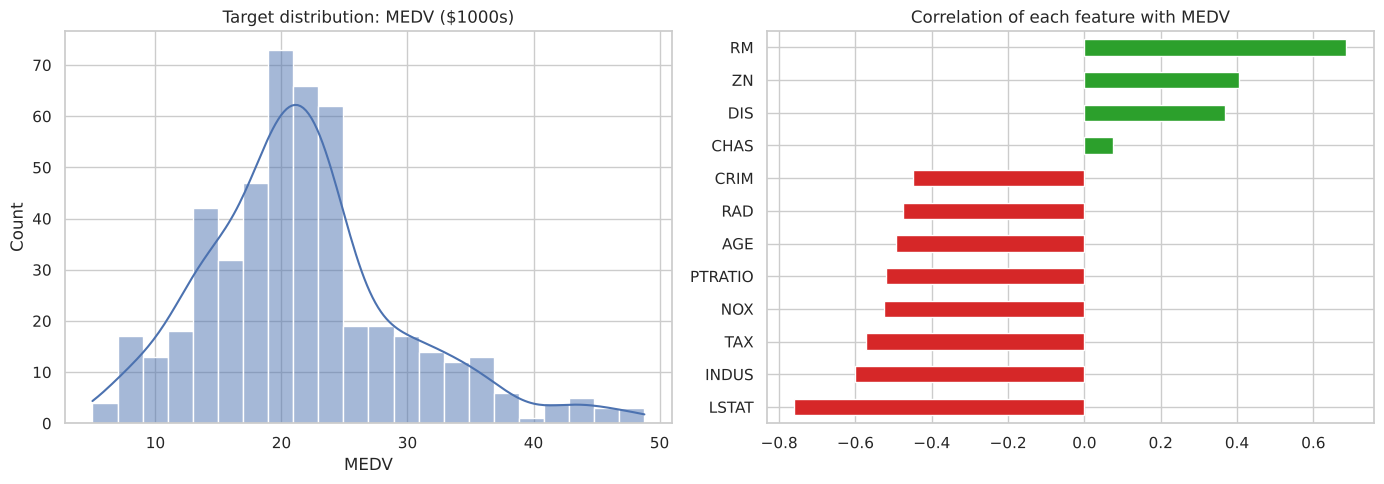

In [5]:
df = df[df["MEDV"] < 50].drop(columns="B").reset_index(drop=True)
print("Shape after cleaning:", df.shape)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df["MEDV"], kde=True, ax=axes[0]); axes[0].set_title("Target distribution: MEDV ($1000s)")
corr = df.corr()["MEDV"].drop("MEDV").sort_values()
corr.plot(kind="barh", ax=axes[1], color=["#d62728" if v < 0 else "#2ca02c" for v in corr])
axes[1].set_title("Correlation of each feature with MEDV")
plt.tight_layout(); plt.savefig(IMG / "eda.png", dpi=120); plt.show()

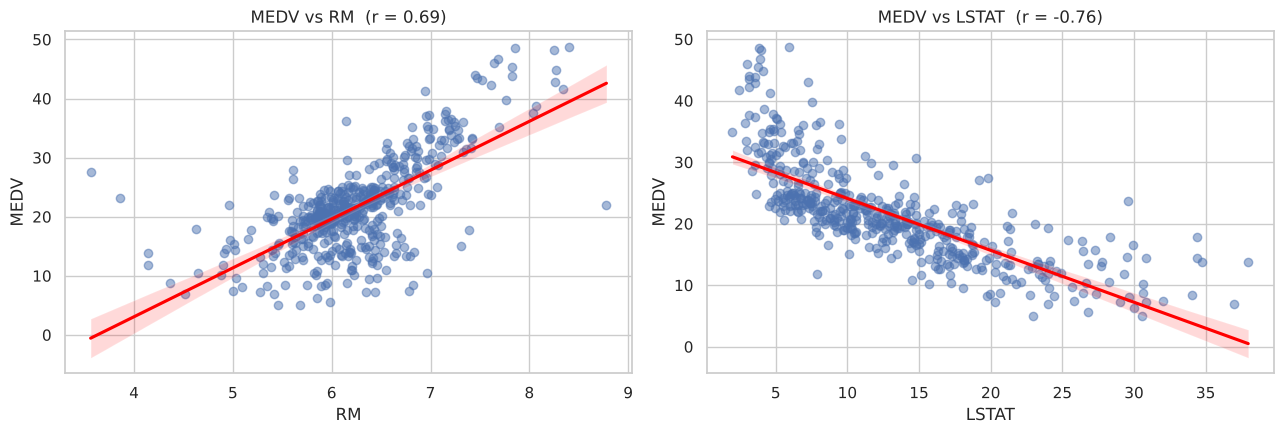

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col in zip(axes, ["RM", "LSTAT"]):
    sns.regplot(data=df, x=col, y="MEDV", ax=ax, scatter_kws={"alpha": .5}, line_kws={"color": "red"})
    ax.set_title(f"MEDV vs {col}  (r = {df[col].corr(df['MEDV']):.2f})")
plt.tight_layout(); plt.savefig(IMG / "top_features.png", dpi=120); plt.show()

## 3. Train / test split

In [7]:
X = df.drop(columns="MEDV")
y = df["MEDV"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (392, 12) | Test: (98, 12)


## 4. Model A — Simple linear regression (one feature: `RM`)
The easiest model to interpret: price as a straight-line function of the number of rooms.

In [8]:
simple = LinearRegression().fit(X_train[["RM"]], y_train)
pred_simple = simple.predict(X_test[["RM"]])
print(f"MEDV = {simple.intercept_:.2f} + {simple.coef_[0]:.2f} × RM")
print(f"→ each extra room adds about ${simple.coef_[0]*1000:,.0f} to the median price")
print(f"Test R²  = {r2_score(y_test, pred_simple):.3f}")
print(f"Test MSE = {mean_squared_error(y_test, pred_simple):.2f}")

MEDV = -29.67 + 8.25 × RM
→ each extra room adds about $8,249 to the median price
Test R²  = 0.378
Test MSE = 31.76


## 5. Model B — Multiple linear regression (all features, standardized)
Features are standardized inside a `Pipeline` so (a) the scaler is fit on the training data only and
(b) the coefficients become directly comparable to each other.

In [9]:
model = Pipeline([("scaler", StandardScaler()), ("lr", LinearRegression())])
model.fit(X_train, y_train)

pred_train = model.predict(X_train)
pred_test = model.predict(X_test)

results = pd.DataFrame({
    "R²": [r2_score(y_train, pred_train), r2_score(y_test, pred_test)],
    "MSE": [mean_squared_error(y_train, pred_train), mean_squared_error(y_test, pred_test)],
    "RMSE ($1000s)": [np.sqrt(mean_squared_error(y_train, pred_train)), np.sqrt(mean_squared_error(y_test, pred_test))],
    "MAE ($1000s)": [mean_absolute_error(y_train, pred_train), mean_absolute_error(y_test, pred_test)],
}, index=["Train", "Test"]).round(3)
results

,R²,MSE,RMSE ($1000s),MAE ($1000s)
Train,0.770,14.638,3.826,2.865
Test,0.758,12.376,3.518,2.692


In [10]:
cv = cross_val_score(model, X, y, cv=KFold(5, shuffle=True, random_state=RANDOM_STATE), scoring="r2")
print(f"5-fold cross-validated R²: {cv.mean():.3f} ± {cv.std():.3f}")

5-fold cross-validated R²: 0.752 ± 0.033


## 6. Interpret the coefficients
Because inputs are standardized, each coefficient = **change in price ($1000s) when that feature goes up by one standard deviation,
holding all other features constant.**

In [11]:
lr = model.named_steps["lr"]
coefs = pd.DataFrame({
    "coefficient (per 1 SD)": lr.coef_,
    "1 SD of feature": X_train.std().values,
}, index=X.columns).sort_values("coefficient (per 1 SD)")
coefs["$ impact per 1 SD"] = (coefs["coefficient (per 1 SD)"] * 1000).round(0)
print(f"Intercept (average price when all features are at their mean): {lr.intercept_:.2f} → ${lr.intercept_*1000:,.0f}")
coefs.round(3)

Intercept (average price when all features are at their mean): 22.03 → $22,029


,coefficient (per 1 SD),1 SD of feature,$ impact per 1 SD
LSTAT,-2.779,7.091,-2779.0
DIS,-2.580,2.121,-2580.0
TAX,-2.262,167.631,-2262.0
PTRATIO,-1.779,2.179,-1779.0
NOX,-1.378,0.115,-1378.0
CRIM,-1.131,7.980,-1131.0
AGE,-0.548,28.312,-548.0
INDUS,-0.377,6.836,-377.0
CHAS,0.058,0.235,58.0
ZN,0.765,23.012,765.0


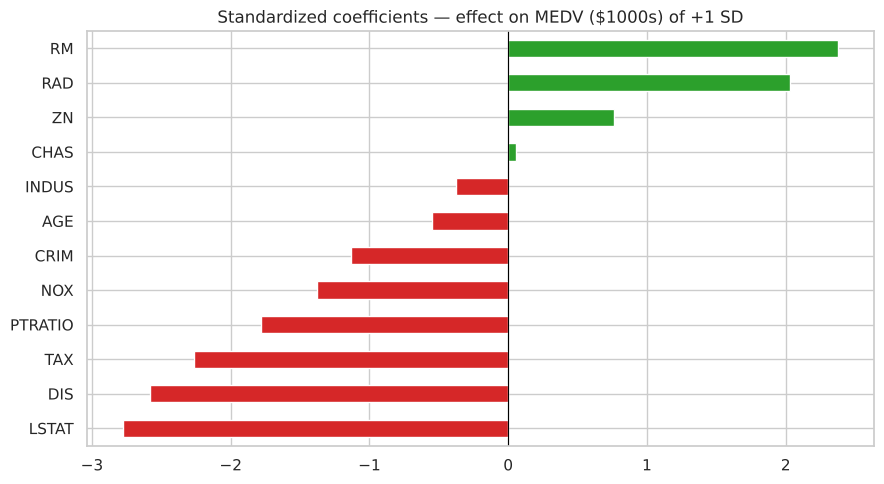

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
coefs["coefficient (per 1 SD)"].plot(kind="barh", ax=ax,
    color=["#d62728" if v < 0 else "#2ca02c" for v in coefs["coefficient (per 1 SD)"]])
ax.axvline(0, color="black", lw=.8)
ax.set_title("Standardized coefficients — effect on MEDV ($1000s) of +1 SD")
plt.tight_layout(); plt.savefig(IMG / "coefficients.png", dpi=120); plt.show()

In [13]:
top_pos = coefs["coefficient (per 1 SD)"].idxmax()
top_neg = coefs["coefficient (per 1 SD)"].idxmin()
print(f"Strongest positive driver : {top_pos} (+{coefs.loc[top_pos, 'coefficient (per 1 SD)']:.2f}k per SD)")
print(f"Strongest negative driver : {top_neg} ({coefs.loc[top_neg, 'coefficient (per 1 SD)']:.2f}k per SD)")

Strongest positive driver : RM (+2.38k per SD)
Strongest negative driver : LSTAT (-2.78k per SD)


## 7. Diagnostics — predicted vs actual and residuals

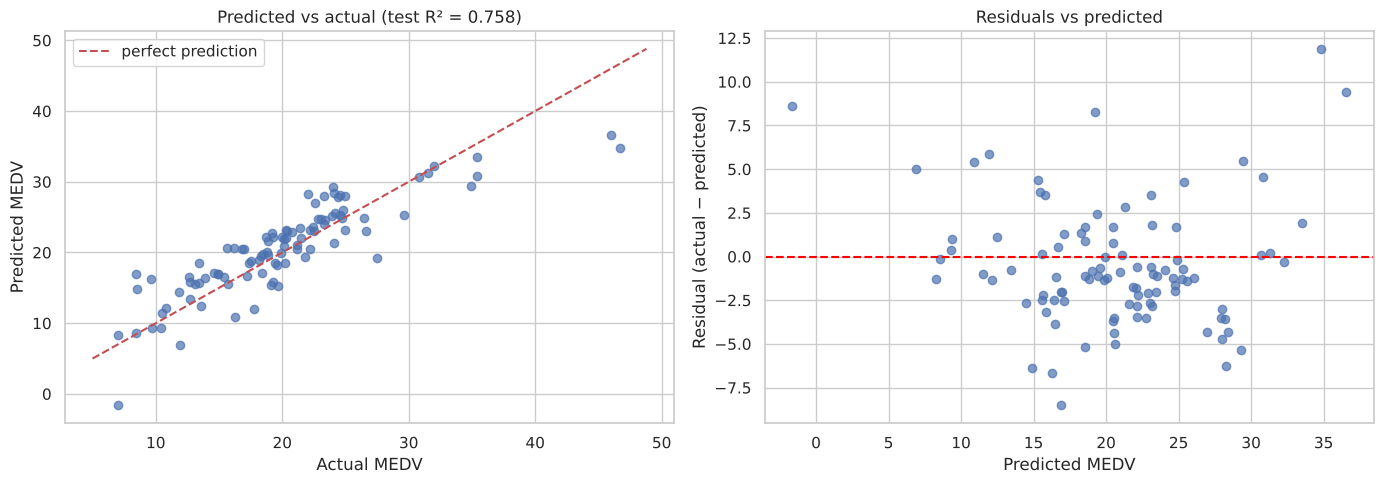

In [14]:
residuals = y_test - pred_test
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_test, pred_test, alpha=.7)
lims = [y.min(), y.max()]
axes[0].plot(lims, lims, "r--", label="perfect prediction")
axes[0].set_xlabel("Actual MEDV"); axes[0].set_ylabel("Predicted MEDV")
axes[0].set_title(f"Predicted vs actual (test R² = {r2_score(y_test, pred_test):.3f})"); axes[0].legend()
axes[1].scatter(pred_test, residuals, alpha=.7)
axes[1].axhline(0, color="red", ls="--")
axes[1].set_xlabel("Predicted MEDV"); axes[1].set_ylabel("Residual (actual − predicted)")
axes[1].set_title("Residuals vs predicted")
plt.tight_layout(); plt.savefig(IMG / "diagnostics.png", dpi=120); plt.show()

## 8. Model comparison

In [15]:
comparison = pd.DataFrame({
    "Model": ["Simple LR (RM only)", "Multiple LR (12 features)"],
    "Test R²": [r2_score(y_test, pred_simple), r2_score(y_test, pred_test)],
    "Test MSE": [mean_squared_error(y_test, pred_simple), mean_squared_error(y_test, pred_test)],
}).round(3)
comparison

,Model,Test R²,Test MSE
0,Simple LR (RM only),0.378,31.763
1,Multiple LR (12 features),0.758,12.376


## Conclusions
* **Simple model (rooms only):** `MEDV ≈ −29.7 + 8.25 × RM` → every additional room adds about **$8.2k**. It explains only
  ~38 % of the variance on the test set (R² = 0.378, MSE = 31.8).
* **Multiple linear regression** explains **~76 %** of the variance on unseen data (**test R² = 0.758, MSE = 12.4**,
  RMSE ≈ $3.5k). Train and test scores are very close (0.770 vs 0.758) and 5-fold CV gives 0.752 ± 0.033, so the model is
  **not overfitting**.
* **Coefficient interpretation** (per +1 standard deviation, all else equal):
  * Price **goes up** with more rooms (`RM` +$2.4k) and better highway access (`RAD` +$2.0k).
  * Price **goes down** with a higher share of lower-status population (`LSTAT` −$2.8k), distance from job centres
    (`DIS` −$2.6k), higher property tax (`TAX` −$2.3k), larger class sizes (`PTRATIO` −$1.8k), pollution (`NOX` −$1.4k)
    and crime (`CRIM` −$1.1k).
  * `RAD` and `TAX` are strongly correlated with each other (r ≈ 0.9), so their individual coefficients should be read with care
    (multicollinearity) — together they mostly cancel out.
* The residual plot shows a slight curve (under-prediction for the most expensive houses), suggesting that a non-linear model
  or log-transforming the target could improve results further.